# Exercise 48 – The simplest neural networks

**Week 9 · Neural networks**

A neural network is built from linear layers $y = wx + b$ and non-linear
activation functions. Starting from a single weight and adding one ingredient
at a time, we fit four data points and see what each building block can (and
cannot) represent.

Each model is trained six times from different random initial weights, which
shows how much the result depends on the initialisation. Parameter names such
as `0.weight` refer to the position of the layer in `nn.Sequential`.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch import nn

from comphy.plotting import annotate, setup_axes
from comphy.training import fit

straight = torch.tensor([[1, -0.5], [2, 0.5], [3, 1.5], [4, 2.5]])
kinked = torch.tensor([[1, 1.0], [2, 1.0], [3, 1.5], [4, 2.5]])
xs = torch.linspace(-2, 5, 300)


class Model1D(nn.Sequential):
    """``nn.Sequential`` that maps a 1D tensor of x-values to a 1D tensor of y-values."""

    def forward(self, x):
        return super().forward(x.reshape(-1, 1)).flatten()


def parameter_text(model):
    return "\n".join(f"{name} = " + ", ".join(f"{v:.2f}" for v in p.detach().flatten().tolist())
                     for name, p in model.named_parameters())


def six_fits(make_model, data, title, color, steps=2000, show_params=True):
    """Train ``make_model()`` from six random initialisations and plot the fits."""
    fig, axes = plt.subplots(2, 3, figsize=(12, 6.5), sharex=True, sharey=True)
    for seed, ax in enumerate(axes.flat):
        torch.manual_seed(seed)
        model = make_model()
        loss = fit(model, data[:, 0], data[:, 1], steps=steps)[-1]
        with torch.no_grad():
            ax.plot(xs, model(xs), color=color)
        ax.plot(data[:, 0], data[:, 1], "o", color="black")
        text = f"MSE = {loss:.3f}"
        if show_params:
            text = parameter_text(model) + "\n" + text
        annotate(ax, text, fontsize=7)
        setup_axes(ax, xlim=(-2, 5), ylim=(-1, 4), xlabel=None, ylabel=None)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## A single weight, no bias: $y = wx$
The line is forced through the origin.

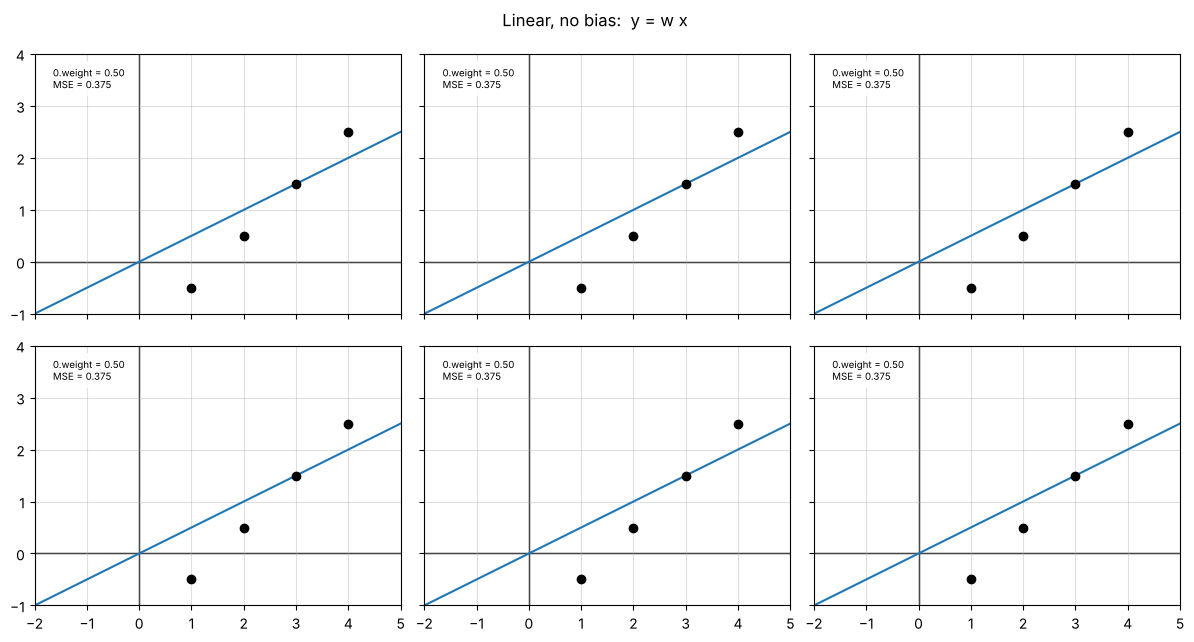

In [2]:
six_fits(lambda: Model1D(nn.Linear(1, 1, bias=False)), straight,
         "Linear, no bias:  y = w x", "C0", steps=1000)

## Weight and bias: $y = wx + b$
Now the straight data is fitted perfectly, every time.

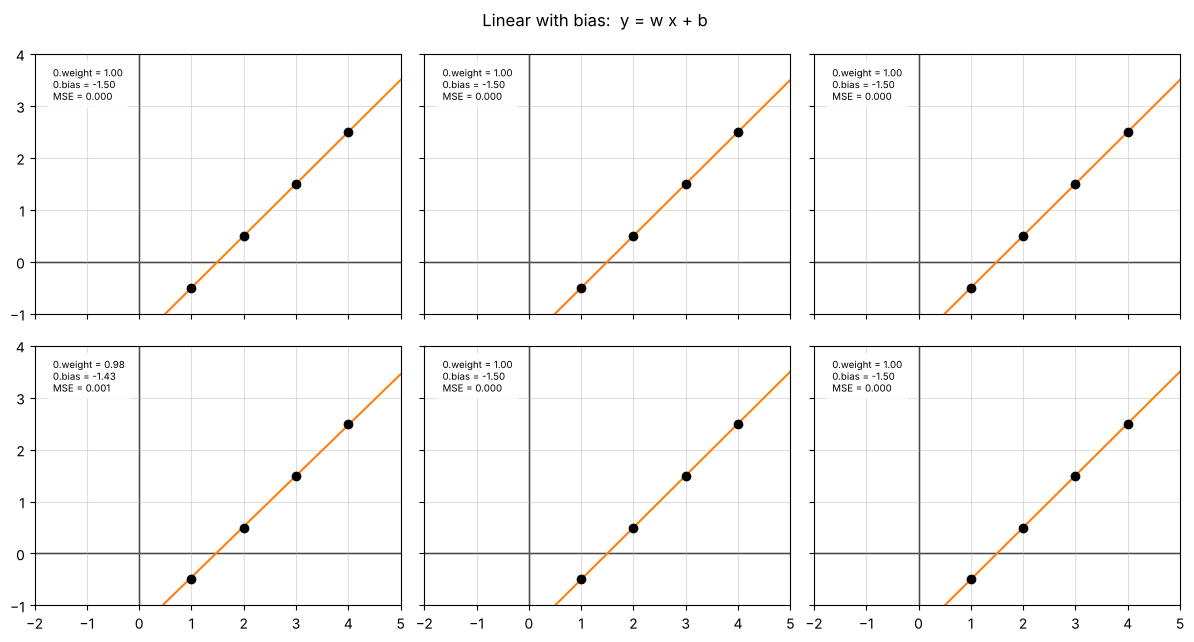

In [3]:
six_fits(lambda: Model1D(nn.Linear(1, 1)), straight, "Linear with bias:  y = w x + b", "C1")

## A kink in the data
A straight line cannot follow the kinked data …

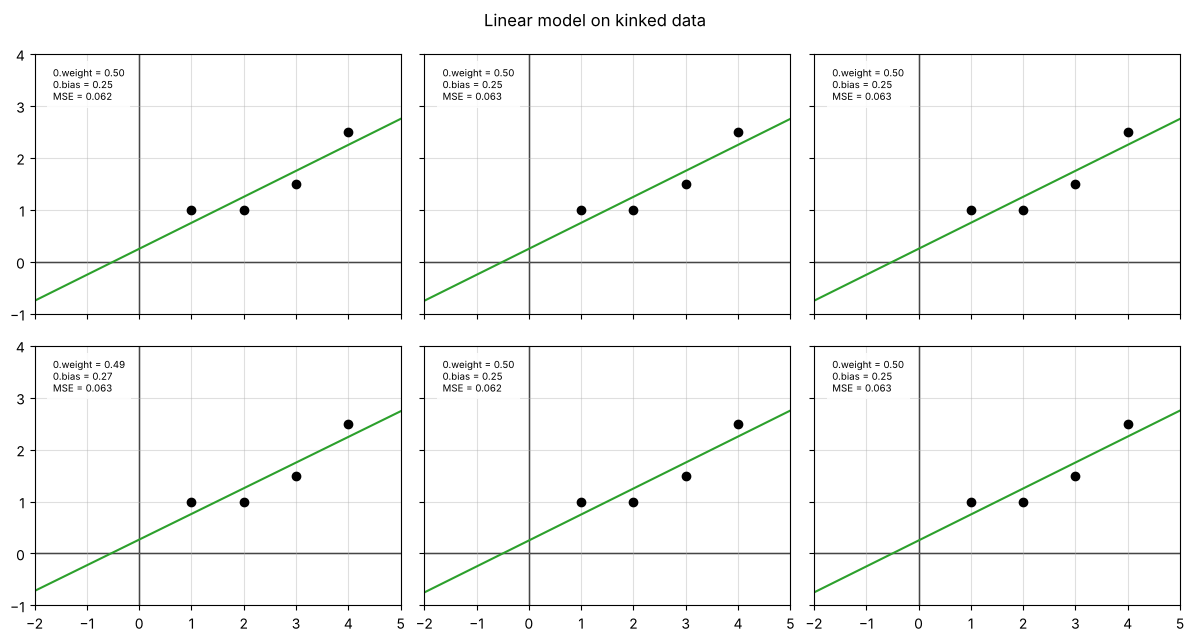

In [4]:
six_fits(lambda: Model1D(nn.Linear(1, 1)), kinked, "Linear model on kinked data", "C2")

… and neither can a single ReLU, $y = \max(0, wx + b)$, since its kink is
always at $y = 0$:

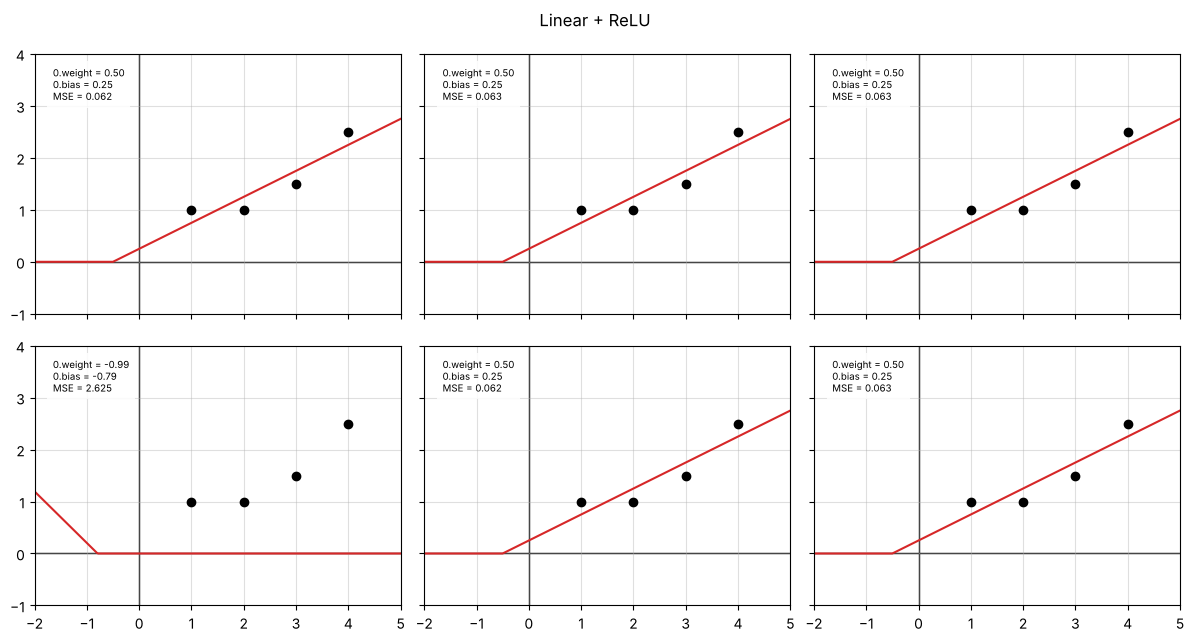

In [5]:
six_fits(lambda: Model1D(nn.Linear(1, 1), nn.ReLU()), kinked, "Linear + ReLU", "C3")

## Two linear layers with ReLU

With a second linear layer after the ReLU, the kink can be moved up to the
level of the data, and both networks below *can* fit it exactly. Whether
they do depends on the initialisation: if a ReLU receives negative input for
every data point it outputs zero, its gradient is zero and it never recovers
(a "dead" ReLU). With a ReLU at the output as well, more runs end up as a
flat line at zero.

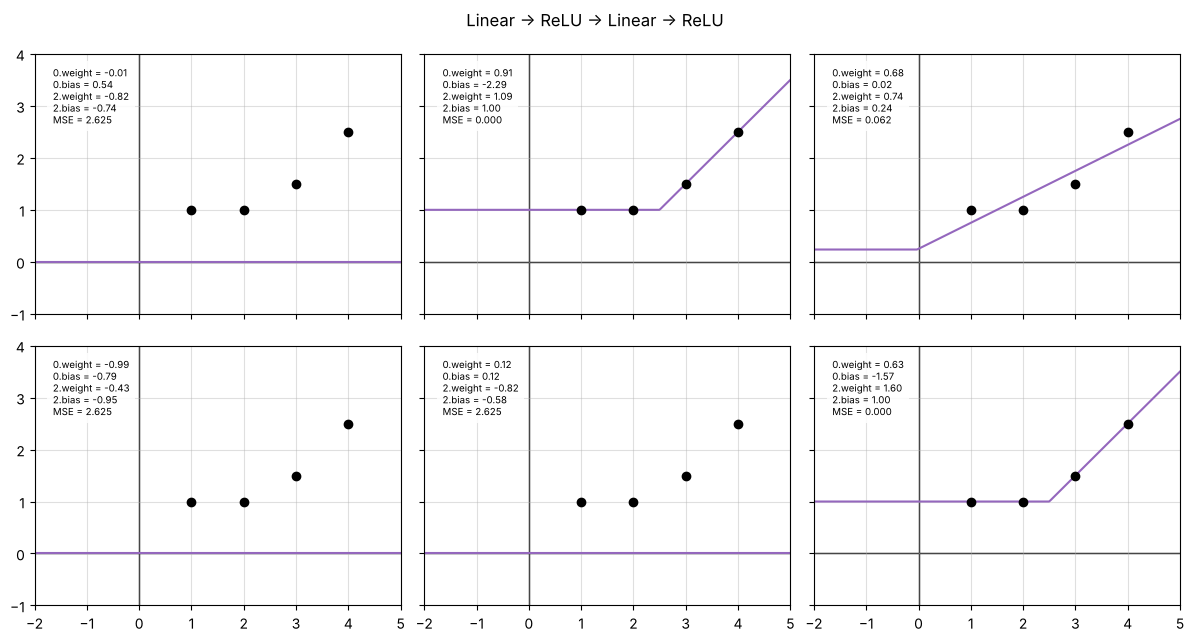

In [6]:
six_fits(lambda: Model1D(nn.Linear(1, 1), nn.ReLU(), nn.Linear(1, 1), nn.ReLU()),
         kinked, "Linear → ReLU → Linear → ReLU", "C4")

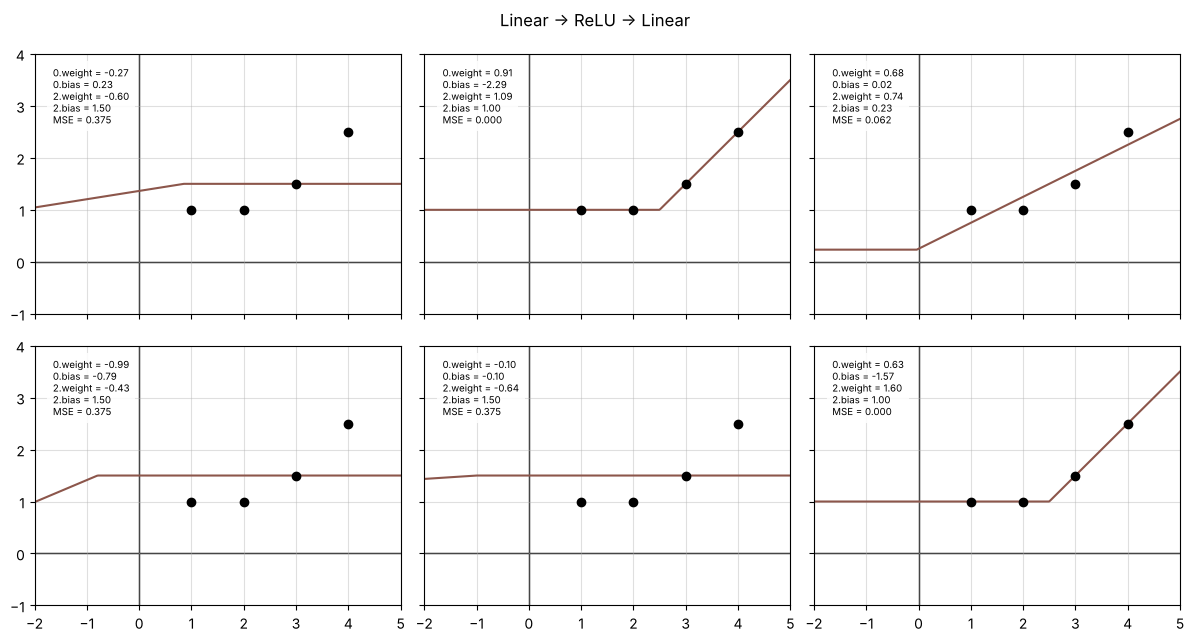

In [7]:
six_fits(lambda: Model1D(nn.Linear(1, 1), nn.ReLU(), nn.Linear(1, 1)),
         kinked, "Linear → ReLU → Linear", "C5")

## Eight hidden neurons
With eight ReLU neurons in the hidden layer there is always at least one
useful kink, so all six fits succeed.

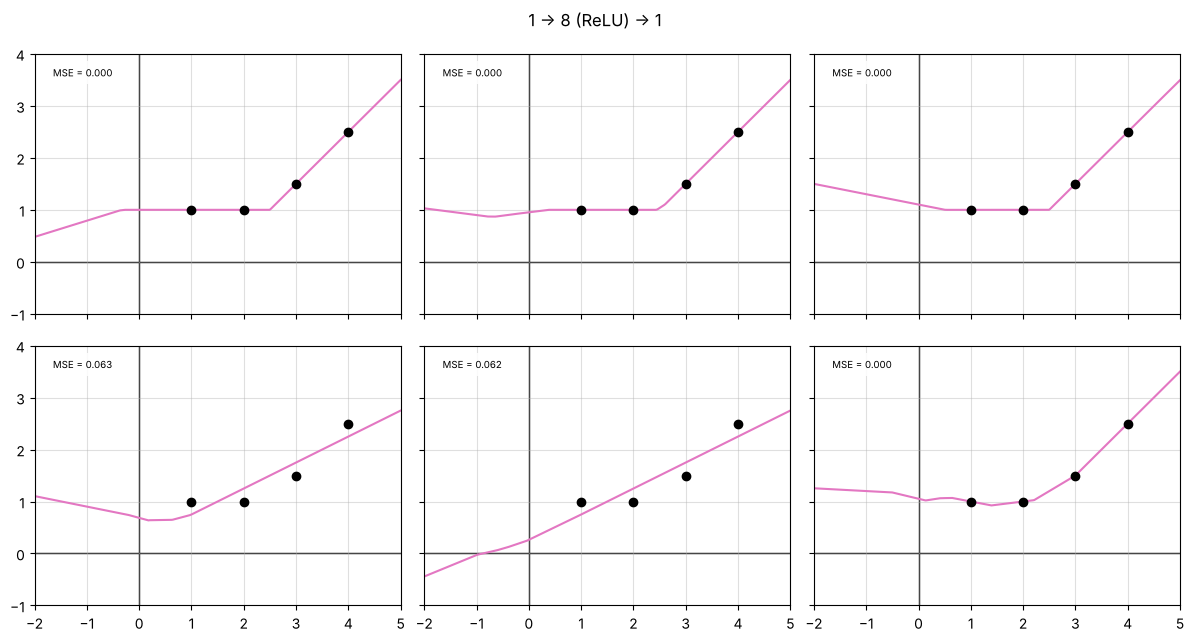

In [8]:
six_fits(lambda: Model1D(nn.Linear(1, 8), nn.ReLU(), nn.Linear(8, 1)),
         kinked, "1 → 8 (ReLU) → 1", "C6", show_params=False)